# Complex analysis 7: Real integrals by residues

*Learning path: complex analysis, part 7 of 8.* [Index](README.md) · Previous: [Residues](06-residues.ipynb) · Next: [Conformal maps](08-conformal-maps.ipynb)

$\displaystyle\int_{-\infty}^\infty \frac{\cos x}{1 + x^2}\,dx = \frac{\pi}{e}$. The integrand is real, the limits are
real, and the answer involves $e$ in a way no substitution from real calculus will produce: $\cos x/(1 + x^2)$ has no
elementary antiderivative. The complex plane gives the answer in three lines. Close the real line with a half circle,
apply the residue theorem, and show the half circle contributes nothing. This lesson does that for four families of
integrals that come up constantly in physics and engineering: rational functions, Fourier integrals, $\sin x/x$, and
integrals over a period.

**Who this is for.** You have done [lesson 6](06-residues.ipynb) and can compute residues.

**What you will be able to do afterwards:**

1. evaluate $\int_{-\infty}^\infty P(x)/Q(x)\,dx$ by closing the contour in the upper half plane;
2. evaluate Fourier integrals $\int R(x)\cos kx\,dx$ with $e^{ikz}$ and Jordan's lemma;
3. handle a pole on the real axis by indenting the contour, and get $\int_0^\infty \sin x/x\,dx = \pi/2$;
4. turn $\int_0^{2\pi} R(\cos\theta, \sin\theta)\,d\theta$ into a contour integral around the unit circle.

Plan about an hour.

## 1. Rational functions: close the contour

To find $\int_{-\infty}^\infty \frac{dx}{1 + x^4}$, integrate $f(z) = 1/(1 + z^4)$ around the closed contour made of the
segment $[-R, R]$ and the upper half circle $C_R$ of radius $R$:

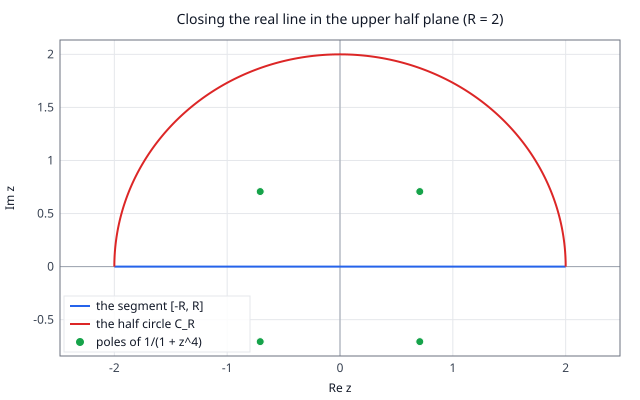

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
p = parametric(t, 0, t, -2, 2);
p = show(p, parametric(2*cos(t), 2*sin(t), t, 0, pi));
p = show(p, scatter([cos(pi/4) cos(3*pi/4) cos(5*pi/4) cos(7*pi/4)], [sin(pi/4) sin(3*pi/4) sin(5*pi/4) sin(7*pi/4)]));
p = legend(p, "the segment [-R, R]", "the half circle C_R", "poles of 1/(1 + z^4)");
labels(title(p, "Closing the real line in the upper half plane (R = 2)"), "Re z", "Im z")

For $R > 1$ the contour encloses the two poles $e^{i\pi/4}$ and $e^{3i\pi/4}$. On $C_R$, $|1 + z^4| \ge R^4 - 1$ and the
length is $\pi R$, so by the ML estimate of lesson 3 the half circle contributes at most $\pi R/(R^4 - 1) \to 0$:

In [2]:
cint(1/(1 + z^4), z, 10*exp(i*t), t, 0, pi)

0.000666638097056

> Contour integral of f dz along z = 10*exp(i*t), t from 0 to pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

What is left as $R \to \infty$ is the real integral, so it equals $2\pi i$ times the two residues:

In [3]:
simplify(2*pi*i*(residue(1/(1 + z^4), z, exp(i*pi/4)) + residue(1/(1 + z^4), z, exp(3*i*pi/4))))
integrate(1/(1 + x^4), x, -inf, inf)

sqrt(2)*pi/2

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

sqrt(2)*pi/2

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

$\pi/\sqrt2 = \sqrt2\,\pi/2$. Galileo's `integrate` uses exactly this method for such integrals. The rule: if $Q$ has no
real zeros and $\deg Q \ge \deg P + 2$, then $\int_{-\infty}^\infty P/Q\,dx = 2\pi i\sum_{\operatorname{Im} a > 0}
\operatorname{Res}(P/Q, a)$.

**Try this.** Compute $\int_{-\infty}^\infty \dfrac{dx}{(x^2 + 1)^2}$ with the double pole at $i$, and check with
`integrate`.

## 2. Fourier integrals and Jordan's lemma

For $\int_{-\infty}^\infty \frac{\cos x}{1 + x^2}\,dx$ it is tempting to use $\cos z/(1 + z^2)$, but that fails:
$\cos(iy) = \cosh y$ grows exponentially up the imaginary axis, so the half circle does not vanish. Use
$e^{iz}/(1 + z^2)$ instead: $|e^{iz}| = e^{-y} \le 1$ in the upper half plane, and the real part of its integral along the
real line is the cosine integral we want.

In [4]:
residue(exp(i*z)/(1 + z^2), z, i)
simplify(2*pi*i*residue(exp(i*z)/(1 + z^2), z, i))
cint(exp(i*z)/(1 + z^2), z, 10*exp(i*t), t, 0, pi)

-i/(2*e)

> Residue of f at z = i: a simple pole: the residue is the limit of (z − a) f as z → a.

pi/e

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

0.007249030076

> Contour integral of f dz along z = 10*exp(i*t), t from 0 to pi: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

The only pole inside is $i$, the residue is $e^{-1}/(2i)$, and $2\pi i$ times it is $\pi/e$. The half circle is
already tiny at $R = 10$. **Jordan's lemma** makes this precise: for $k > 0$ and $g(z) \to 0$ as $|z| \to \infty$,
$\int_{C_R} g(z)e^{ikz}\,dz \to 0$, even when $g$ decays only like $1/z$, because $e^{ikz}$ is exponentially small
except near the ends of the half circle. Galileo does the same:

In [5]:
integrate(cos(x)/(x^2 + 1), x, -inf, inf)
integrate(cos(2*x)/(x^2 + 1), x, -inf, inf)

pi/e

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

pi/exp(2)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

The second answer, $\pi e^{-2}$, shows the pattern: $\int \cos kx/(1 + x^2)\,dx = \pi e^{-|k|}$. In physics this says
that the Fourier transform of a Lorentzian line shape is a decaying exponential, the link between the width of a
spectral line and the lifetime of the state that emits it.

**Try this.** Compute $\int_{-\infty}^\infty \dfrac{x\sin x}{x^2 + 1}\,dx$ with $ze^{iz}/(z^2 + 1)$, and compare with
`integrate`.

## 3. A pole on the real line: $\sin x/x$

$\int_0^\infty \frac{\sin x}{x}\,dx$, the **Dirichlet integral**, is needed everywhere from signal processing to
diffraction. Use $e^{iz}/z$: its pole at 0 is on the contour, so go round it on a small half circle $c_\epsilon$ of
radius $\epsilon$ above 0. The closed contour then encloses no pole, so its integral is 0. As $\epsilon \to 0$ the small
half circle, traversed clockwise, contributes $-\pi i$ times the residue (half of a full turn):

In [6]:
residue(exp(i*z)/z, z, 0)
cint(exp(i*z)/z, z, exp(i*t)/1000, t, pi, 0)

1

> Residue of f at z = 0: a simple pole: the residue is the limit of (z − a) f as z → a.

-3.1395926537*i

> Contour integral of f dz along z = exp(i*t)/1000, t from pi to 0: the integral of f(z(t)) z'(t) dt, computed numerically with Simpson's rule on 4096 steps.

The small half circle gives $-\pi i$, up to a correction of order $\epsilon = 1/1000$. With the big half circle vanishing by Jordan's lemma, the two real pieces add up to
$\pi i$: $\int_{-\infty}^\infty \frac{e^{ix}}{x}\,dx = \pi i$ in the principal-value sense, whose imaginary part is
$\int_{-\infty}^\infty \frac{\sin x}{x}\,dx = \pi$. The integrand is even, so

In [7]:
integrate(sin(x)/x, x, 0, inf)

pi/2

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

In general a simple pole on the contour contributes $\pi i$ times its residue, half of the $2\pi i$ of a pole inside.

**Try this.** Use the same indentation to find $\int_{-\infty}^\infty \dfrac{\sin x}{x(x^2 + 1)}\,dx$. There are two
poles to account for: $0$ on the line and $i$ above it.

## 4. Integrals over a period

An integral $\int_0^{2\pi} R(\cos\theta, \sin\theta)\,d\theta$ is already a contour integral in disguise. With
$z = e^{i\theta}$ on the unit circle,

$$\cos\theta = \frac{z + z^{-1}}{2}, \qquad \sin\theta = \frac{z - z^{-1}}{2i}, \qquad d\theta = \frac{dz}{iz}.$$

For $\int_0^{2\pi} \frac{d\theta}{2 + \cos\theta}$ this gives $\oint \frac{2\,dz}{i(z^2 + 4z + 1)}$, with poles at
$-2 \pm \sqrt3$. Only $-2 + \sqrt3$ is inside the unit circle:

In [8]:
poles(2/(i*(z^2 + 4*z + 1)), z)
simplify(2*pi*i*residue(2/(i*(z^2 + 4*z + 1)), z, -2 + sqrt(3)))
integrate(1/(2 + cos(t)), t, 0, 2*pi)

[-sqrt(3)-2, 1,  i/sqrt(3);
  sqrt(3)-2, 1, -i/sqrt(3)]

> Poles: one row [pole, order, residue] for each zero of the denominator that the numerator does not cancel.

2*sqrt(3)*pi/3

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

2*pi/sqrt(3)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

$2\pi/\sqrt3$. The same substitution handles any rational function of $\cos\theta$ and $\sin\theta$; Galileo's
`integrate` applies it when the interval is a full period:

In [9]:
integrate(sin(t)^2/(5 + 4*cos(t)), t, 0, 2*pi)

pi/4

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

**Try this.** Show that $\int_0^{2\pi} \dfrac{d\theta}{a + \cos\theta} = \dfrac{2\pi}{\sqrt{a^2 - 1}}$ for $a > 1$ by
the substitution, and check $a = 3$ with `integrate`.

## Summary

* **Rational functions:** close in the upper half plane; with $\deg Q \ge \deg P + 2$ and no real poles,
  $\int_{-\infty}^\infty P/Q = 2\pi i\sum_{\operatorname{Im} a > 0}\operatorname{Res}$.
* **Fourier integrals:** use $R(z)e^{ikz}$ ($k > 0$), not $\cos kz$; Jordan's lemma kills the half circle even when $R$
  decays like $1/z$. $\int \cos kx/(1 + x^2) = \pi e^{-|k|}$.
* **Poles on the line:** indent around them; a simple pole contributes $\pi i$ times its residue.
  $\int_0^\infty \sin x/x = \pi/2$.
* **Periods:** $z = e^{i\theta}$ turns $\int_0^{2\pi} R(\cos\theta, \sin\theta)\,d\theta$ into residues inside the unit
  circle.

Next: [conformal maps](08-conformal-maps.ipynb), where analytic functions become geometry.

## Exercises

1. **Degree.** Evaluate $\int_{-\infty}^\infty \dfrac{x^2}{1 + x^4}\,dx$ by residues.
2. **A shifted Lorentzian.** Evaluate $\int_{-\infty}^\infty \dfrac{dx}{x^2 + 2x + 5}$. Where is the pole in the upper half
   plane?
3. **Fourier.** Show that $\int_{-\infty}^\infty \dfrac{\cos x}{(x^2 + 4)^2}\,dx = \dfrac{3\pi}{16e^2}$.
4. **Period.** Evaluate $\int_{-\pi}^{\pi} \dfrac{d\theta}{3 - 2\sin\theta}$.
5. **Squared sinc.** Show that $\int_{-\infty}^\infty \dfrac{\sin^2 x}{x^2}\,dx = \pi$. (Hint: $\sin^2 x = (1 - \cos 2x)/2$,
   and use $(1 - e^{2iz})/z^2$ with an indentation at 0. Check numerically with
   `2*nintegrate(sin(x)^2/x^2, x, 0.000001, 400)`, which misses a tail of about $1/400$.)

## Hints and answers

* **Section 1, Try this.** $\operatorname{Res}(1/(z^2 + 1)^2, i) = -i/4$, so the integral is $\pi/2$.
* **Section 2, Try this.** The residue of $ze^{iz}/(z^2 + 1)$ at $i$ is $e^{-1}/2$; $2\pi i e^{-1}/2 = \pi i/e$, whose
  imaginary part is $\pi/e$.
* **Section 3, Try this.** $\pi i\operatorname{Res}_0 + 2\pi i\operatorname{Res}_i$ for $e^{iz}/(z(z^2 + 1))$ is
  $\pi i - \pi i/e$, so the integral is $\pi(1 - 1/e)$.
* **Section 4, Try this.** The pole inside is $z = -a + \sqrt{a^2 - 1}$; for $a = 3$ the answer is $2\pi/\sqrt8 =
  \pi/\sqrt2$.
* **Exercise 1.** $\pi/\sqrt2$, the same as $\int dx/(1 + x^4)$.
* **Exercise 2.** The pole is at $-1 + 2i$; the integral is $\pi/2$.
* **Exercise 3.** The double pole at $2i$ has residue $-3ie^{-2}/32$ for $e^{iz}/(z^2 + 4)^2$.
* **Exercise 4.** $2\pi/\sqrt5$.
* **Exercise 5.** The indentation gives $\pi i\cdot\operatorname{Res}_0 = \pi i\cdot(-2i)/2 = \pi$ for the real part.

## Sources

1. A. L. Cauchy, *Mémoire sur les intégrales définies* (1814, published 1827).
2. C. Jordan, *Cours d'analyse de l'École Polytechnique*, vol. 2 (1894), for the lemma.
3. E. M. Stein and R. Shakarchi, *Complex Analysis*, Princeton University Press (2003), chapter 2, section 2.
4. M. J. Ablowitz and A. S. Fokas, *Complex Variables: Introduction and Applications*, 2nd ed., Cambridge University
   Press (2003), chapter 4.